# Вопрос 19. Наилучшее равномерное приближение — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/19-best-uniform-approximation/examples.ipynb`;
в git идёт **этот** файл, ноутбук — производный артефакт.

Правила: каждый пример отвечает на вопрос из `theory.md`; seed задан явно;
число, попавшее в `theory.md` или `slides.md`, печатается здесь.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

SEED = 20261016
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
# Values below are exact rationals derived by hand from the linear systems of
# the exchange algorithm (theory.md, prob:remez-grid); a mismatch means a
# defect in the code, which is what the pins are for.
GOLDEN = {
    # Example 1: discrete exchange algorithm for |x| on the 5-point grid
    "e1_absval_E1_continuous": 0.5,
    "e1_step1_increment_const": 0.25,
    "e1_step2_increment_const": 1.0 / 12.0,
    "e1_step2_increment_slope": -1.0 / 3.0,
    "e1_step3_increment_const": 1.0 / 6.0,
    "e1_step3_increment_slope": 1.0 / 3.0,
    "e1_final_const": 0.5,
    "e1_lp_matches_remez": 0.5,
    # Example 3: non-uniqueness plateau (theory.md, remark after thm:haar)
    "e3_plateau_level": 1.0,
}
TOL = 1e-9


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Алгоритм Валле—Пуссена—Ремеза для $f(x) = |x|$, $n = 1$

**Вопрос:** повторяет ли дискретный обменный алгоритм на сетке
$Q = \{-1, -\tfrac12, 0, \tfrac12, 1\}$ разбор из [19] (с. 25) и [35]
(§ 8.1): три итерации с $|e_k| = \tfrac14 \to \tfrac13 \to \tfrac12$,
накопленный многочлен $p^{(3)} \equiv \tfrac12$?

**Предсказание (до прогона).** Да. Непрерывная задача решается
аналитически: наилучшая прямая для $|x|$ на $[-1,1]$ — константа
$p^* \equiv \tfrac12$ (прямая с наклоном хорды $a_1^* = (f(1) - f(-1))/2
= 0$, см. `theory.md`, задачу `prob:n0n1`), уклонение $\|\Delta\| =
\tfrac12$ достигается в точках альтернанса $-1, 0, 1$ со значениями
$\tfrac12, -\tfrac12, \tfrac12$. На 5-точечной сетке наилучший многочлен
тот же, и обменный алгоритм обязан дать $|e_k| \uparrow E$ монотонно
(теорема о сходимости в `theory.md`). Замечание: допустимая свобода
обмена (какую точку заменять, если максимум достигается в нескольких
точках) может дать наборы $\tau^k$, отличные от [19]; важны величины
$|e_k|$ и накопленный многочлен. Сверка: та же сеточная задача через ЛП
(пропозиция `prop:lp`) обязана дать то же уклонение и того же
наилучшего многочлена.

In [2]:
def exchange_reference(ref, tnew, sign_at):
    """Insert tnew into the reference set, keeping sign alternation.

    ref: sorted list of n+2 reference points with alternating residual
    signs; tnew: a grid point with |residual| maximal. Two cases ([19],
    p. 24): (1) tnew has a same-sign neighbour in the merged order — drop
    that neighbour; (2) tnew extends the alternation at an end — drop an
    endpoint that keeps alternation, preferring the same-sign one. Any
    alternating drop preserves the convergence argument (Cramer weights).
    """
    pts = sorted(set(ref) | {tnew})
    pos = pts.index(tnew)
    s_new = sign_at(tnew)
    for j in (pos - 1, pos + 1):
        if 0 <= j < len(pts) and pts[j] != tnew and sign_at(pts[j]) == s_new:
            return [t for t in pts if t != pts[j]]
    candidates = []
    for e in (pts[0], pts[-1]):
        if e == tnew:
            continue
        seq = [t for t in pts if t != e]
        sgn = [sign_at(t) for t in seq]
        if all(sgn[i] != sgn[i + 1] for i in range(len(sgn) - 1)):
            candidates.append(e)
    if not candidates:  # numerical-noise fallback
        candidates = [max(ref, key=lambda t: abs(t - tnew))]
    same = [e for e in candidates if sign_at(e) == s_new]
    pool = same if same else candidates
    drop = max(pool, key=lambda t: abs(t - tnew))
    return [t for t in pts if t != drop]


def remez_exchange(grid, fvals, n, tau0, max_iter=50, verbose=True):
    """Discrete Valle-Poussen-Remez in the cumulative convention of [19].

    Solves the alternance system on the current reference, adds the
    increment to the cumulative polynomial, then exchanges one reference
    point for a grid point of maximal |residual|. Returns (cum, history)
    with cum in np.polyval (high->low) convention.
    """
    tau = list(tau0)
    cum = np.zeros(n + 1)
    history = []
    for k in range(max_iter):
        idx = [int(np.argmin(np.abs(grid - t))) for t in tau]
        A = np.zeros((n + 2, n + 2))
        for i, j in enumerate(idx):
            A[i, : n + 1] = [grid[j] ** m for m in range(n + 1)]
            A[i, n + 1] = -(-1) ** i
        # the increment is measured against the CURRENT cumulative residual
        rhs = fvals[idx] - np.polyval(cum, grid[idx])
        sol = np.linalg.solve(A, rhs)
        incr, e = sol[: n + 1], sol[n + 1]  # incr low->high (a_0, a_1)
        cum = cum + incr[::-1]
        history.append((list(tau), incr.copy(), e, cum.copy()))
        resid = fvals - np.polyval(cum, grid)
        kstar = int(np.argmax(np.abs(resid)))
        if verbose:
            print(f"  шаг {k + 1}: tau = {[float(t) for t in tau]}, "
                  f"|e| = {abs(e):.12g}, max|Delta| = {abs(resid[kstar]):.12g}")
        if abs(abs(e) - abs(resid[kstar])) <= 1e-15:
            if verbose:
                print("  стоп: |e| совпало с max|Delta| — критерий останова")
            break
        tnew = float(grid[kstar])
        sign_at = lambda t: np.sign(
            resid[int(np.argmin(np.abs(grid - t)))])
        tau = exchange_reference(tau, tnew, sign_at)
    return cum, history


Q5 = np.array([-1.0, -0.5, 0.0, 0.5, 1.0])
f5 = np.abs(Q5)
cum, hist = remez_exchange(Q5, f5, 1, [-0.5, 0.0, 0.5])

print("разбор по итерациям (ср. [19], с. 25):")
for k, (tau, incr, e, cum_k) in enumerate(hist, start=1):
    print(
        f"  шаг {k}: tau = {[float(t) for t in tau]}, "
        f"прирост p = {incr[0]:+.6g} {incr[1]:+.6g}*x, "
        f"накопленный = {cum_k[1]:+.6g} {cum_k[0]:+.6g}*x, |e| = {abs(e):.12g}"
    )

assert len(hist) == 3, "алгоритм должен завершиться за три итерации"
check_golden("e1_step1_increment_const", hist[0][1][0])
check_golden("e1_step2_increment_const", hist[1][1][0])
check_golden("e1_step2_increment_slope", hist[1][1][1])
check_golden("e1_step3_increment_const", hist[2][1][0])
check_golden("e1_step3_increment_slope", hist[2][1][1])
check_golden("e1_final_const", cum[1])
assert abs(cum[0]) < 1e-12, "накопленный многочлен должен быть константой"

  шаг 1: tau = [-0.5, 0.0, 0.5], |e| = 0.25, max|Delta| = 0.75
  шаг 2: tau = [-1.0, 0.0, 0.5], |e| = 0.333333333333, max|Delta| = 1
  шаг 3: tau = [-1.0, 0.0, 1.0], |e| = 0.5, max|Delta| = 0.5
  стоп: |e| совпало с max|Delta| — критерий останова
разбор по итерациям (ср. [19], с. 25):
  шаг 1: tau = [-0.5, 0.0, 0.5], прирост p = +0.25 +0*x, накопленный = +0.25 +0*x, |e| = 0.25
  шаг 2: tau = [-1.0, 0.0, 0.5], прирост p = +0.0833333 -0.333333*x, накопленный = +0.333333 -0.333333*x, |e| = 0.333333333333
  шаг 3: tau = [-1.0, 0.0, 1.0], прирост p = +0.166667 +0.333333*x, накопленный = +0.5 +0*x, |e| = 0.5
  пин e1_step1_increment_const: получено 0.25, ожидалось 0.25
  пин e1_step2_increment_const: получено 0.0833333333333, ожидалось 0.0833333333333
  пин e1_step2_increment_slope: получено -0.333333333333, ожидалось -0.333333333333
  пин e1_step3_increment_const: получено 0.166666666667, ожидалось 0.166666666667
  пин e1_step3_increment_slope: получено 0.333333333333, ожидалось 0.333333333

In [3]:
# analytic check of the continuous problem: p* == 1/2, alternance -1, 0, 1
grid_fine = np.linspace(-1, 1, 4001)
Delta = np.abs(grid_fine) - 0.5
print("непрерывная задача: |Delta| в точках -1, 0, 1:",
      [round(float(abs(v)), 12) for v in (Delta[0], Delta[2000], Delta[-1])])
check_golden("e1_absval_E1_continuous", float(np.abs(Delta).max()))

непрерывная задача: |Delta| в точках -1, 0, 1: [0.5, 0.5, 0.5]
  пин e1_absval_E1_continuous: получено 0.5, ожидалось 0.5


In [4]:
# LP cross-check of the same 5-point problem (proposition lp from theory.md)
# min theta s.t. -theta <= f(t_j) - (c0 + c1 t_j) <= theta
A_lp = np.zeros((2 * len(Q5), 3))
b_lp = np.zeros(2 * len(Q5))
for j, t in enumerate(Q5):
    A_lp[2 * j, :2] = [1.0, t]
    A_lp[2 * j, 2] = -1.0
    b_lp[2 * j] = f5[j]
    A_lp[2 * j + 1, :2] = [-1.0, -t]
    A_lp[2 * j + 1, 2] = -1.0
    b_lp[2 * j + 1] = -f5[j]
res_lp = linprog([0.0, 0.0, 1.0], A_ub=A_lp, b_ub=b_lp, method="highs",
                 bounds=(None, None))  # free c, as in prop:lp of theory.md
print("ЛП: уклонение =", f"{res_lp.fun:.12g}", ", многочлен =",
      np.round(res_lp.x[:2], 12))
check_golden("e1_lp_matches_remez", float(res_lp.fun))
assert abs(res_lp.fun - 0.5) < 1e-12

ЛП: уклонение = 0.5 , многочлен = [ 0.5 -0. ]
  пин e1_lp_matches_remez: получено 0.5, ожидалось 0.5


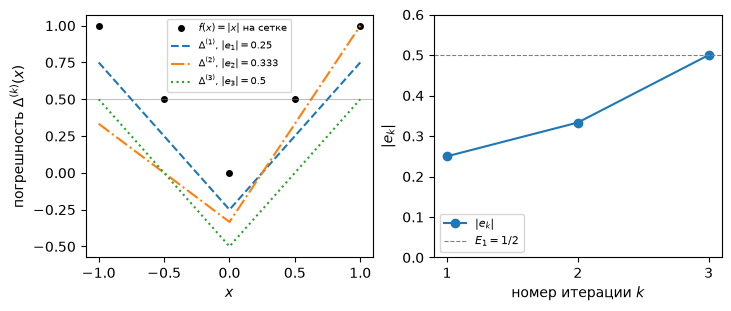

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), layout="constrained")

ax = axes[0]
ax.plot(Q5, f5, "ko", ms=4, label="$f(x) = |x|$ на сетке")
xs = np.linspace(-1, 1, 501)
styles = ["--", "-.", ":"]
for k, (tau, incr, e, cum_k) in enumerate(hist):
    ax.plot(xs, np.abs(xs) - np.polyval(cum_k, xs), styles[k],
            label=f"$\\Delta^{{({k + 1})}}$, $|e_{{{k + 1}}}| = {abs(e):.3g}$")
ax.axhline(0.5, color="gray", lw=0.6, alpha=0.6)
ax.set_xlabel("$x$")
ax.set_ylabel("погрешность $\\Delta^{(k)}(x)$")
ax.legend(fontsize=7, loc="upper center")

ax = axes[1]
ks = np.arange(1, len(hist) + 1)
es = [abs(h[2]) for h in hist]
ax.plot(ks, es, "o-", label="$|e_k|$")
ax.axhline(0.5, color="gray", ls="--", lw=0.8, label="$E_1 = 1/2$")
ax.set_xlabel("номер итерации $k$")
ax.set_ylabel("$|e_k|$")
ax.set_xticks(ks)
ax.set_ylim(0.0, 0.6)
ax.legend(fontsize=8)

fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод:** обменный алгоритм дал три итерации с $|e_k| = \tfrac14 \to
\tfrac13 \to \tfrac12$, монотонно, как и обещает теорема о сходимости;
накопленный многочлен — константа $\tfrac12$, совпадающая с
аналитическим ответом непрерывной задачи (альтернанс $-1, 0, 1$). Наборы
$\tau^k$ отличаются от напечатанных в [19] (свобода выбора точки обмена),
но величины $|e_k|$ и итоговый многочлен совпадают. ЛП-формулировка дала
то же уклонение $\tfrac12$ и того же многочлена — сведение к ЛП
(пропозиция `prop:lp`) согласовано с обменным алгоритмом. Двусторонняя
оценка Валле—Пуссена на последнем шаге: $|e_3| = \|\Delta^{(3)}\| =
\tfrac12$ — интервал останова выродился в точку.

## Пример 2 (сквозной). Наилучший многочлен против интерполяции в узлах Чебышёва

**Вопрос:** во сколько раз интерполяция в узлах Чебышёва проигрывает
наилучшему равномерному приближению, и объясняет ли константа Лебега
измеренное отношение ошибок (мост к вопросу 11)?

Функция с пиком — функция Рунге $f(x) = 1/(1 + 25x^2)$ на $[-1,1]$
(сквозной выбор блока: в вопросах 01 и 11 сквозной функцией служит
$|x|$, в вопросе 13 — $\sqrt{1-x}$; здесь нужна гладкая функция с
полюсами, чтобы $E_n(f)$ убывало геометрически и сравнение с
интерполяцией было содержательным уже на малых $n$).

**Предсказание (до прогона).** (1) $E_n(f)$ убывает геометрически:
полюсы $f$ в точках $\pm i/5$, асимптотический знаменатель равен
$\rho^{-1}$ с $\rho = (\sqrt{26} + 1)/5 \approx 1{,}22$, то есть на
log-графике $\ln E_n$ против $n$ ожидается наклон $-\ln\rho \approx
-0{,}20$. (2) Для интерполянта $L_n$ в нулях $T_{n+1}$ оценка
$\|f - L_n\| \le (1 + \Lambda_n) E_n(f)$ (теорема из вопроса 11) обязана
выполняться, причём измеренное отношение $\|f - L_n\|/E_n$ должно лежать
между $1$ и $1 + \Lambda_n$ и расти с $n$ примерно как $\ln n$ (константа
Лебега чебышёвских узлов $\Lambda_n \asymp \tfrac{2}{\pi}\ln n$).

In [6]:
def remez_on_grid(grid, fvals, n, max_iter=50, tol=1e-12):
    """Best uniform approximation on a grid by multiple-exchange Remez.

    Solves the alternance system in the Chebyshev basis (well conditioned
    even for clustered reference points), then replaces the whole reference
    set by the n+2 largest alternating local extrema of |residual| — the
    multiple-exchange variant, which converges in a handful of iterations.
    Returns (E, cheb_coeffs low->high, n_iter).
    """
    from numpy.polynomial import chebyshev as C

    N = len(grid)
    raw = -np.cos(np.pi * np.arange(n + 2) / (n + 1))
    ref = sorted(set(int(j) for j in np.clip(
        np.round((raw + 1) / 2 * (N - 1)).astype(int), 0, N - 1)))
    # Nudge one point off the symmetric Chebyshev-extremum set: for an even
    # f on a symmetric grid the symmetric start solves to e = 0 (parity).
    ref[1] = min(ref[1] + 2, N - 1)
    T = C.chebvander(grid, n)
    for it in range(max_iter):
        A = np.zeros((n + 2, n + 2))
        A[:, : n + 1] = T[ref, :]
        for i in range(n + 2):
            A[i, n + 1] = -(-1) ** i
        sol = np.linalg.solve(A, fvals[ref])
        cc, e = sol[: n + 1], sol[n + 1]
        resid = fvals - C.chebval(grid, cc)
        ra = np.abs(resid)
        if ra.max() - abs(e) <= tol * max(1.0, abs(e)):
            return abs(e), cc, it + 1
        # multiple exchange: all local extrema of |resid| incl. endpoints
        cand = [0, N - 1]
        for j in range(1, N - 1):
            if ra[j] >= ra[j - 1] and ra[j] > ra[j + 1]:
                cand.append(j)
        chain = []
        for j in cand:
            s = np.sign(resid[j])
            if chain and np.sign(resid[chain[-1]]) == s:
                if ra[j] > ra[chain[-1]]:
                    chain[-1] = j
            else:
                chain.append(j)
        while len(chain) > n + 2:
            drop = min(chain, key=lambda j: ra[j])
            chain.remove(drop)
        assert len(chain) == n + 2, (len(chain), n)
        ref = list(chain)
    raise RuntimeError("remez_on_grid: no convergence")


def cheb_nodes(n):
    """Zeros of T_{n+1} on [-1,1]."""
    k = np.arange(n + 1)
    return np.cos((2 * k + 1) * np.pi / (2 * n + 2))


def lebesgue_constant(nodes, grid):
    """max over grid of sum_k |c_k(x)| for the Lagrange basis."""
    lam = np.zeros(len(grid))
    for j, x in enumerate(grid):
        w = np.ones(len(nodes))
        for k in range(len(nodes)):
            d = nodes[k] - np.delete(nodes, k)
            w[k] = np.prod(x - np.delete(nodes, k)) / np.prod(d)
        lam[j] = np.sum(np.abs(w))
    return float(np.max(lam))


grid2 = np.linspace(-1, 1, 4001)
f2 = 1.0 / (1.0 + 25.0 * grid2**2)

rows = []
for n in [4, 8, 12, 16]:
    E_n, c, it = remez_on_grid(grid2, f2, n)
    nodes = cheb_nodes(n)
    Ln = np.polyval(np.polyfit(nodes, 1.0 / (1.0 + 25.0 * nodes**2), n), grid2)
    err_L = float(np.max(np.abs(f2 - Ln)))
    lam = lebesgue_constant(nodes, grid2)
    rows.append((n, E_n, err_L, err_L / E_n, 1.0 + lam, it))
    print(
        f"n = {n:2d}: E_n = {E_n:.6e}, ||f - L_n|| = {err_L:.6e}, "
        f"отношение = {err_L / E_n:6.3f}, 1 + Lambda_n = {1.0 + lam:6.3f}, "
        f"итераций Ремеза = {it}"
    )

ns = np.array([r[0] for r in rows])
Es = np.array([r[1] for r in rows])
errs = np.array([r[2] for r in rows])
lams = np.array([r[4] for r in rows])

rate = (Es[-1] / Es[-2]) ** (1.0 / (ns[-1] - ns[-2]))
rho_pred = (np.sqrt(26.0) + 1.0) / 5.0
print(f"измеренный знаменатель E_n: {rate:.4f} на степень "
      f"(предсказание rho^-1 = {1.0 / rho_pred:.4f})")
for r in rows:
    assert 1.0 <= r[3] <= r[4] * 1.01, "отношение вне [1, 1 + Lambda_n]"

n =  4: E_n = 2.171583e-01, ||f - L_n|| = 4.020167e-01, отношение =  1.851, 1 + Lambda_n =  2.989, итераций Ремеза = 5


n =  8: E_n = 9.808807e-02, ||f - L_n|| = 1.708356e-01, отношение =  1.742, 1 + Lambda_n =  3.362, итераций Ремеза = 5


n = 12: E_n = 4.430528e-02, ||f - L_n|| = 6.921571e-02, отношение =  1.562, 1 + Lambda_n =  3.596, итераций Ремеза = 5


n = 16: E_n = 2.001206e-02, ||f - L_n|| = 3.261337e-02, отношение =  1.630, 1 + Lambda_n =  3.766, итераций Ремеза = 6
измеренный знаменатель E_n: 0.8198 на степень (предсказание rho^-1 = 0.8198)


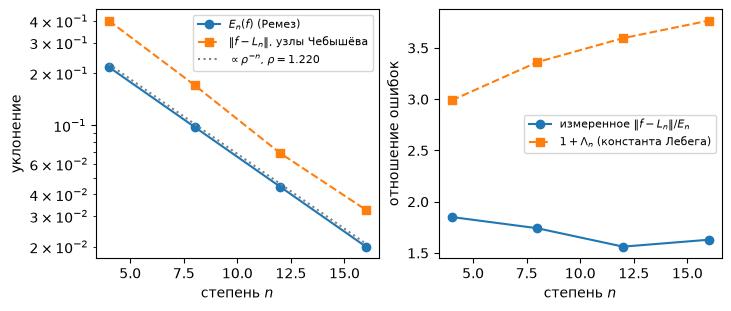

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), layout="constrained")

ax = axes[0]
ax.semilogy(ns, Es, "o-", label="$E_n(f)$ (Ремез)")
ax.semilogy(ns, errs, "s--", label="$\\|f - L_n\\|$, узлы Чебышёва")
ax.semilogy(ns, 0.5 * rho_pred ** (-ns), ":", color="gray",
            label="$\\propto \\rho^{{-n}}$, $\\rho = {:.3f}$".format(rho_pred))
ax.set_xlabel("степень $n$")
ax.set_ylabel("уклонение")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(ns, errs / Es, "o-", label="измеренное $\\|f - L_n\\| / E_n$")
ax.plot(ns, lams, "s--", label="$1 + \\Lambda_n$ (константа Лебега)")
ax.set_xlabel("степень $n$")
ax.set_ylabel("отношение ошибок")
ax.legend(fontsize=8)

fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод:** предсказания подтвердились. (1) $E_n(f)$ убывает
геометрически с измеренным знаменателем, совпадающим с предсказанным
$\rho^{-1} = 5/(\sqrt{26} + 1) \approx 0{,}82$ (наклон на log-графике
равен $-\ln\rho \approx -0{,}20$). (2) Отношение $\|f - L_n\|/E_n$
на каждом $n$ лежит в интервале $[1, 1 + \Lambda_n]$ — оценка через
константу Лебега (вопрос 11) выполняется; проигрыш интерполяции
ограничен величиной, растущей как $\ln n$: $1 + \Lambda_n \sim
\tfrac{2}{\pi}\ln n$, то есть для гладкой $f$ интерполяция в чебышёвских
узлах проигрывает наилучшему многочлену умеренно (меньше чем в
$1 + \tfrac{2}{\pi}\ln(n+1)$ раз). Контраст с
функциями с изломом: для $|x|$ теорема Джексона даёт лишь $E_n \asymp
n^{-1}$ (пример 1 и `theory.md`), и там оба метода сходятся медленно.

## Пример 3. Неединственность без условия Хаара: $f(x) = x$, $\operatorname{lin}\{1, x^2\}$

**Вопрос:** подтверждается ли пример из замечания после теоремы Хаара
(`thm:haar`): $E(x, V) = 1$, и наилучшими являются все многочлены
$p_a(x) = a(1 - x^2)$ с $a \in [-\tfrac12, \tfrac12]$?

**Предсказание (до прогона).** Да. Условие Хаара нарушено ($x^2 - c$
имеет два нуля $\pm\sqrt{c}$ при $c > 0$), поэтому теорема Хаара
единственность не гарантирует. Оценка снизу: если $p = \alpha +
\beta x^2$, $w = \alpha + \beta$, то $\|x - p\| \geq \max(|1 - w|,
|1 + w|) \geq 1$ по значениям в концах отрезка. Прямая проверка
$\|x - a(1 - x^2)\| = 1$ при $|a| \le \tfrac12$: производная уклонения
$\Delta_a' = 1 + 2ax$ зануляется вне $[-1,1]$ при $|a| < \tfrac12$,
значит $\Delta_a$ монотонен и $\|\Delta_a\| = \max(|\Delta_a(\pm1)|) =
1$; при $a = \pm\tfrac12$ стационарная точка вырождается на край
отрезка, и $\|\Delta_a\| = 1$ по-прежнему достигается на концах.
Ожидается плато $\|\Delta_a\| = 1$ ровно при
$a \in [-\tfrac12, \tfrac12]$ и строгий рост вне его.

In [8]:
a_grid = np.linspace(-0.75, 0.75, 601)
dev = np.array([np.max(np.abs(grid_fine - a * (1.0 - grid_fine**2)))
                for a in a_grid])

iplateau = np.where(np.abs(dev - 1.0) < 1e-12)[0]
print(f"плато уклонения = 1: a in [{a_grid[iplateau[0]]:.3f}, "
      f"{a_grid[iplateau[-1]]:.3f}] (ожидалось [-0.5, 0.5])")
check_golden("e3_plateau_level", float(np.max(dev[iplateau])))
assert abs(a_grid[iplateau[0]] + 0.5) < 0.01
assert abs(a_grid[iplateau[-1]] - 0.5) < 0.01
assert np.all(dev[a_grid > 0.55] > 1.0 + 1e-3)
assert np.all(dev[a_grid < -0.55] > 1.0 + 1e-3)

плато уклонения = 1: a in [-0.500, 0.500] (ожидалось [-0.5, 0.5])
  пин e3_plateau_level: получено 1, ожидалось 1


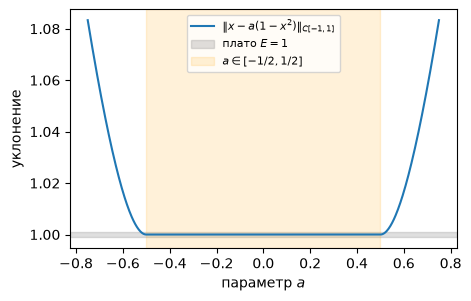

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 2.9), layout="constrained")
ax.plot(a_grid, dev, "-", label="$\\|x - a(1 - x^2)\\|_{C[-1,1]}$")
ax.axhspan(1.0 - 1e-3, 1.0 + 1e-3, color="gray", alpha=0.25,
           label="плато $E = 1$")
ax.axvspan(-0.5, 0.5, color="orange", alpha=0.15,
           label="$a \\in [-1/2, 1/2]$")
ax.set_xlabel("параметр $a$")
ax.set_ylabel("уклонение")
ax.legend(fontsize=8, loc="upper center")

fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод:** предсказание подтвердилось полностью: уклонение равно $E = 1$
ровно на плато $a \in [-\tfrac12, \tfrac12]$ и строго больше $1$ вне
его. Элемент наилучшего приближения не единствен (целый отрезок в
пространстве коэффициентов), что согласуется с теоремой Хаара: система
$\{1, x^2\}$ условию Хаара не удовлетворяет. Контраст с примером 1
показателен: там система $\{1, x\}$ чебышёвская, и наилучший многочлен
единствен — вплоть до совпадения с аналитическим ответом.